# Belguith Ahmed Rami — 22516111
# Benboubaker Majdi — 22517042

In [1]:
import os
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg


import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.layers import TextVectorization
from tensorflow.keras.utils import register_keras_serializable
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from keras.models import load_model
from tensorflow.keras.metrics import Mean
from tensorflow.keras.layers import Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.models import load_model

# Pour utiliser au mieux le GPU
AUTOTUNE = tf.data.AUTOTUNE

2026-01-18 16:43:41.564184: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/rami/miniconda3/lib/python3.12/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [2]:
# Classe utile pour la partie Clip mais il fallait bien regarder pour la trouver
@register_keras_serializable()
class L2Normalize(layers.Layer):
    def __init__(self, axis=-1, **kwargs):
        super().__init__(**kwargs)
        self.axis = axis

    def call(self, inputs):
        return tf.math.l2_normalize(inputs, axis=self.axis)

    def get_config(self):
        config = super().get_config()
        config.update({"axis": self.axis})
        return config

In [3]:
# ============================
# SmallBERT encoder
# ============================
@register_keras_serializable()
class SmallBERT(tf.keras.Model):
    def __init__(self, sequence_length, vocab_size, embed_dim, num_heads,
                 ff_dim, num_layers, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.num_layers = num_layers

        self.pos_embedding = PositionalEmbedding(sequence_length, vocab_size,
                                                 embed_dim)

        self.transformer_blocks = [
            TransformerBlock(embed_dim,
                             num_heads, ff_dim) for _ in range(num_layers)
        ]
        self.layernorm = tf.keras.layers.LayerNormalization(epsilon=1e-6)
        self.dropout = tf.keras.layers.Dropout(0.1)

    def call(self, inputs, training=False):
        x = self.pos_embedding(inputs)
        for block in self.transformer_blocks:
            x = block(x, training=training)
        x = self.layernorm(x)
        return self.dropout(x, training=training)

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "vocab_size": self.vocab_size,
            "embed_dim": self.embed_dim,
            "num_heads": self.num_heads,
            "ff_dim": self.ff_dim,
            "num_layers": self.num_layers,
        })
        return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)

In [4]:
# ============================
# TransformerBlock
# ============================
@tf.keras.utils.register_keras_serializable()
class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads,ff_dim, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)
        self.supports_masking = True
        self.att = layers.MultiHeadAttention(num_heads=num_heads,
                                             key_dim=embed_dim)
        self.ffn = tf.keras.Sequential([
            layers.Dense(ff_dim, activation="relu"),
            layers.Dense(embed_dim),
        ])
        self.layernorm1 = layers.LayerNormalization(epsilon=1e-6)
        self.layernorm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(dropout_rate)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, inputs, training=False, mask=None):
        seq_len = tf.shape(inputs)[1]
        attn_mask = None
        if mask is not None:
            attn_mask = tf.cast(mask[:, tf.newaxis, :], dtype=tf.float32)
            attn_mask = tf.tile(attn_mask, [1, seq_len, 1])

        attn_output = self.att(inputs, inputs, inputs, attention_mask=attn_mask)
        attn_output = self.dropout1(attn_output, training=training)
        out1 = self.layernorm1(inputs + attn_output)
        ffn_output = self.ffn(out1)
        ffn_output = self.dropout2(ffn_output, training=training)
        return self.layernorm2(out1 + ffn_output)

        def get_config(self):
            config = super().get_config()
            config.update({
                "embed_dim": self.att.key_dim,
                "num_heads": self.att.num_heads,
                "ff_dim": self.ffn.layers[0].units,
                "dropout_rate": self.dropout1.rate,
            })
            return config

    @classmethod
    def from_config(cls, config):
        return cls(**config)# ============================
# PositionalEmbedding Layer
# ============================
@tf.keras.utils.register_keras_serializable()
class PositionalEmbedding(layers.Layer):
    def __init__(self, sequence_length, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.token_embeddings = layers.Embedding(input_dim=vocab_size,
                                                 output_dim=embed_dim)
        self.position_embeddings = layers.Embedding(input_dim=sequence_length,
                                                    output_dim=embed_dim)
        self.sequence_length = sequence_length
        self.vocab_size = vocab_size
        self.embed_dim = embed_dim

    def call(self, inputs):
        length = tf.shape(inputs)[-1]
        positions = tf.range(0, length)
        embedded_tokens = self.token_embeddings(inputs)
        embedded_positions = self.position_embeddings(positions)
        return embedded_tokens + embedded_positions

    def compute_mask(self, inputs, mask=None):
        return tf.not_equal(inputs, 0)

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "vocab_size": self.vocab_size,
            "embed_dim": self.embed_dim,
        })
        return config

In [5]:
@register_keras_serializable()
class MaskedMean(layers.Layer):
  # Retourne la moyenne des mots sans être trop influencé par PAD
    def call(self, inputs):
        seq_out, token_ids = inputs   # (B,L,D), (B,L)
        mask = tf.cast(tf.not_equal(token_ids, 0), seq_out.dtype)  # PAD=0
        mask = tf.expand_dims(mask, -1)        # (B,L,1)
        summed = tf.reduce_sum(seq_out * mask, axis=1)             # (B,D)
        counts = tf.reduce_sum(mask, axis=1)                        # (B,1)
        return summed / tf.maximum(counts, 1.0)

In [6]:
# Perte contrastive CLIP
# Le but de cette fonction est d’aligner les embeddings d’images et de textes
# correspondants dans un espace latent partgé. Elle est inspirée du papier
# CLIP, où l'on entraîne le modèle à prédire quelle image correspond à quel
# texte et réciproquement.

@register_keras_serializable(package="clip")
class ClipLossLayer(layers.Layer):
    def __init__(self, temperature=0.07, **kwargs):
        super().__init__(**kwargs)
        self.temperature = temperature
        self.clip_loss_metric = tf.keras.metrics.Mean(name="clip_loss")

    def call(self, inputs):
        # l'inputs est forcément (img, txt) ou [img, txt]
        img, txt = inputs  # (B, D) attention il faut avoir L2-normalisés !!

        # Matrice des similarités (cosinus parce qu'on a L2 zt ça simplifie)
        logits = tf.matmul(img, txt, transpose_b=True) / self.temperature

        # Les Labels implicites : c'est la diagonale
        labels = tf.range(tf.shape(logits)[0])

        li = tf.keras.losses.sparse_categorical_crossentropy(labels,
                                                             logits,
                                                             from_logits=True)
        lt = tf.keras.losses.sparse_categorical_crossentropy(labels,
                                                          tf.transpose(logits),
                                                          from_logits=True)
        loss = tf.reduce_mean(li + lt) / 2.0

        # Ca c'est super important car on ajoute la loss au graphe
        # du modèle et ça nous simplifie la vie
        # après on met à jour la métrique interne si on veut la suivre
        self.add_loss(loss)
        self.clip_loss_metric.update_state(loss)

        # On retourne un TUPLE de tenseurs(surtout pas une liste)
        # dc facileà récupérer
        return (img, txt)

    def get_config(self):
        return {**super().get_config(), "temperature": self.temperature}


In [7]:
def make_clip_dataset_smallbert(
    captions_csv_path,
    tokenizer_layer,
    batch_size=32,
    shuffle=True,
    drop_remainder=True,
    cache=True,
    seed=42,
):
    """
    Construit un tf.data.Dataset avec en sortie (images, token_ids) pour CLIP.
    """
    # On récupère le fichier captions.csv qui a tout
    df = pd.read_csv(captions_csv_path)
    image_paths = df["image_path"].astype(str).tolist()
    captions    = df["caption"].fillna("").astype(str).tolist()

    # Récupération du répertoire des images
    root = Path(dataset_dir)
    full_paths = [str(root / p) for p in image_paths]

    # Création du dataset d'image
    ds = tf.data.Dataset.from_tensor_slices((full_paths, captions))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(full_paths), seed=seed,
                        reshuffle_each_iteration=True)

    # Chargement d'une ensemble d'images normalisées et de tokens (le texte)
    IMAGE_H, IMAGE_W = 224, 224  # même que image_size

    def load_sample(img_path, caption):
        img = tf.io.read_file(img_path)
        img = tf.image.decode_jpeg(img, channels=3)
        img = tf.image.resize(img, [224, 224])
        img = tf.image.convert_image_dtype(img, tf.float32)  # [0,1]
        tokens = tf.cast(tokenizer_layer(caption), tf.int32)  # (L,)
        # x = dict des 2 entrées, pour forcer à ne pas avoir de  y
        return {"image_input": img, "text_input": tokens}

    # Pour utiliser le cache et pouvoir faire les traitements en //
    ds = ds.map(load_sample, num_parallel_calls=AUTOTUNE)
    if cache:
        ds = ds.cache()
    # si drop_remainder=True on vire le dernier batch
    # s'il n'est pas de la bonne taille
    ds = ds.batch(batch_size, drop_remainder=drop_remainder).prefetch(AUTOTUNE)
    return ds

In [8]:

def plot_training_curves(history, save_path=None):
    """Plots only loss (and val_loss if available)."""
    h = history.history  # Keras History dict

    loss = h.get("loss", [])
    val_loss = h.get("val_loss", [])

    epochs = range(1, len(loss) + 1)

    plt.figure(figsize=(6, 4))
    plt.plot(epochs, loss, label="Train Loss")

    if len(val_loss) == len(loss) and len(val_loss) > 0:
        plt.plot(epochs, val_loss, label="Validation Loss")

    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300)

    plt.show()


In [9]:
# =========================
# 2) Build encoders from saved classifiers
# =========================

In [10]:
def build_image_encoder_from_saved_classifier(image_classifier_path, embed_dim=128):
    clf = tf.keras.models.load_model(image_classifier_path, custom_objects={"L2Normalize": L2Normalize}, compile=False)
    feat = clf.get_layer("flatten").output
    emb = layers.Dense(embed_dim, activation=None, name="img_embed")(feat)
    emb = L2Normalize(name="img_l2norm")(emb)
    return Model(clf.input, emb, name="image_encoder")


def build_text_encoder_from_saved_classifier(text_classifier_path, embed_dim=128):
    clf = tf.keras.models.load_model(
        text_classifier_path,
        custom_objects={
            "L2Normalize": L2Normalize,
            "MaskedMean": MaskedMean,
            "PositionalEmbedding": PositionalEmbedding,
            "TransformerBlock": TransformerBlock,
            "SmallBERT": SmallBERT,
        },
        compile=False
    )
    pooled = clf.get_layer("masked_mean").output
    emb = layers.Dense(embed_dim, activation=None, name="txt_embed")(pooled)
    emb = L2Normalize(name="txt_l2norm")(emb)
    return Model(clf.input, emb, name="text_encoder")


# =========================
# 3) Build CLIP model
# =========================

In [11]:

model_dir = "./models_forclip"
vocab_path = os.path.join(model_dir, "vocab.txt")
sequence_length = 32

def load_vocab_txt(path: str) -> list[str]:
    with open(path, "r", encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]

def build_tokenizer_from_vocab(vocab: list[str], seq_len: int) -> TextVectorization:
    tok = TextVectorization(
        output_sequence_length=seq_len,
        standardize=None,   # keep exactly as training expected
    )
    tok.set_vocabulary(vocab)
    return tok

vocab = load_vocab_txt(vocab_path)
text_tokenizer = build_tokenizer_from_vocab(vocab, sequence_length)
print("✅ Tokenizer ready | vocab size:", len(vocab))

✅ Tokenizer ready | vocab size: 4121


I0000 00:00:1768751024.411529    9343 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2242 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1650 Ti with Max-Q Design, pci bus id: 0000:01:00.0, compute capability: 7.5


In [12]:

def build_clip_model(image_encoder, text_encoder, image_shape=(224, 224, 3), sequence_length=32, temperature=0.07):
    img_in = Input(shape=image_shape, name="image_input")
    txt_in = Input(shape=(sequence_length,), dtype="int32", name="text_input")

    img_emb = image_encoder(img_in)
    txt_emb = text_encoder(txt_in)

    img_out, txt_out = ClipLossLayer(temperature=temperature, name="clip_loss")([img_emb, txt_emb])

    clip_model = Model(
        inputs={"image_input": img_in, "text_input": txt_in},
        outputs=[img_out, txt_out],
        name="clip_model"
    )
    return clip_model


def run_clip_training_with_your_dataset_fn(
    captions_csv_path,
    model_dir,
    vocab_size=10000,
    sequence_length=32,
    embed_dim=128,
    batch_size=32,   # ✅ 64 → 32
    epochs=5,
    lr=1e-4,
    temperature=0.07
):
    os.makedirs(model_dir, exist_ok=True)

    df = pd.read_csv(captions_csv_path)
    df = df.sample(frac=1.0, random_state=42).reset_index(drop=True)
    
    n = len(df)
    train_end = int(0.8 * n)
    val_end   = int(0.9 * n)
    
    df_train = df.iloc[:train_end]
    df_val   = df.iloc[train_end:val_end]
    df_test  = df.iloc[val_end:]
    
    train_csv = os.path.join(model_dir, "train.csv")
    val_csv   = os.path.join(model_dir, "val.csv")
    test_csv  = os.path.join(model_dir, "test.csv")
    
    df_train.to_csv(train_csv, index=False)
    df_val.to_csv(val_csv, index=False)
    df_test.to_csv(test_csv, index=False)
    
    captions_train = df_train["caption"].fillna("").astype(str).tolist()
    text_tokenizer.adapt(captions_train)  # adapt TRAIN only
    
    train_dataset = make_clip_dataset_smallbert(train_csv, text_tokenizer, batch_size=batch_size, drop_remainder=True)
    val_dataset   = make_clip_dataset_smallbert(val_csv,   text_tokenizer, batch_size=batch_size, drop_remainder=True)
    test_dataset  = make_clip_dataset_smallbert(test_csv,  text_tokenizer, batch_size=batch_size, drop_remainder=False)

    
    # Sanity check
    b = next(iter(train_dataset))
    print("Batch shapes:", b["image_input"].shape, b["text_input"].shape)
    # attendu : (32, 224, 224, 3) et (32, 32)

    # Encoders
    img_clf_path = os.path.join(model_dir, "image_classifier.keras")
    txt_clf_path = os.path.join(model_dir, "text_classifier_smallbert.keras")

    image_encoder = build_image_encoder_from_saved_classifier(
        img_clf_path, embed_dim=embed_dim
    )
    text_encoder = build_text_encoder_from_saved_classifier(
        txt_clf_path, embed_dim=embed_dim
    )

    # CLIP model
    clip_model = build_clip_model(
        image_encoder=image_encoder,
        text_encoder=text_encoder,
        image_shape=(224, 224, 3),
        sequence_length=sequence_length,
        temperature=temperature
    )
    clip_model.compile(
        optimizer=tf.keras.optimizers.Adam(lr)
    )
    clip_model.summary()
    best_ckpt_path = os.path.join(model_dir, "clip_model_best.keras")

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=4,       
            min_delta=1e-4,
            restore_best_weights=True,
            verbose=1
        ),
        tf.keras.callbacks.ModelCheckpoint(
            filepath=best_ckpt_path,
            monitor="val_loss",
            save_best_only=True,
            save_weights_only=False,  # sauvegarde le modèle complet
            mode="min",
            verbose=1
        )]
    # Train
    history = clip_model.fit(train_dataset, validation_data=val_dataset, epochs=epochs,callbacks=callbacks)
    test_loss = clip_model.evaluate(test_dataset)
    print("Test loss:", test_loss)


    # Save
    clip_path = os.path.join(model_dir, "clip_model.keras")
    clip_model.save(clip_path)
    print("CLIP sauvegardé:", clip_path)

    # Reload test
    clip_loaded = tf.keras.models.load_model(
        clip_path,
        custom_objects={
            "L2Normalize": L2Normalize,
            "MaskedMean": MaskedMean,
            "PositionalEmbedding": PositionalEmbedding,
            "TransformerBlock": TransformerBlock,
            "SmallBERT": SmallBERT,
            "ClipLossLayer": ClipLossLayer,
        }
    )
    print("Reload OK:", clip_loaded.name)

    _ = clip_loaded(b, training=False)
    print("Forward pass OK after reload.")

    return clip_model, clip_loaded, text_tokenizer, history


# =========================
# 5) Exemple d’utilisation (IMPORTANT: dataset_dir doit être défini globalement)
# =========================

2026-01-18 16:43:46.108901: W tensorflow/core/kernels/data/cache_dataset_ops.cc:917] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


Batch shapes: (32, 224, 224, 3) (32, 32)


Model: "clip_model"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_input          │ (None, 32)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_encoder       │ (None, 128)       │ 12,939,328 │ image_input[0][0] │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_encoder        │ (None, 128)       │  1,961,344 │ text_input[0][0]  │
│ (Functional)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ clip_loss           │ [(None, 128),     │          0 │ image_encoder[0]… │
│ (ClipLossLayer)     │ (None, 128)]      │            │ text_encoder[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,900,672 (56.84 MB)

 Trainable params: 14,900,224 (56.84 MB)

... (4 outputs left out)

2026-01-18 16:44:15.519288: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:546] Omitted potentially buggy algorithm eng14{k25=2} for conv (f32[32,32,224,224]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,3,224,224]{3,2,1,0}, f32[32,3,3,3]{3,2,1,0}, f32[32]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]}
2026-01-18 16:44:15.795857: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:546] Omitted potentially buggy algorithm eng14{k25=2} for conv (f32[32,64,112,112]{3,2,1,0}, u8[0]{0}) custom-call(f32[32,32,112,112]{3,2,1,0}, f32[64,32,3,3]{3,2,1,0}, f32[64]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_targe


Epoch 1: val_loss improved from None to 3.49078, saving model to ./models_forclip/clip_model_best.keras

Epoch 1: finished saving model to ./models_forclip/clip_model_best.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 31s 353ms/step - clip_loss: 4.2039 - loss: 4.2039 - val_clip_loss: 3.4908 - val_loss: 3.4908
Epoch 2/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - clip_loss: 3.3944 - loss: 3.3944
Epoch 2: val_loss improved from 3.49078 to 3.47471, saving model to ./models_forclip/clip_model_best.keras

Epoch 2: finished saving model to ./models_forclip/clip_model_best.keras
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 178ms/step - clip_loss: 3.4160 - loss: 3.4160 - val_clip_loss: 3.4747 - val_loss: 3.4747
Epoch 3/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - clip_loss: 3.1179 - loss: 3.1179
Epoch 3: val_loss did not improve from 3.47471
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 117ms/step - clip_loss: 3.1720 - loss: 3.1720 - val_clip_loss: 3.4930 - val_loss: 3.4930
Epoch 4/10
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - clip_lo

2026-01-18 16:44:34.088919: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:546] Omitted potentially buggy algorithm eng14{k25=2} for conv (f32[16,32,224,224]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,3,224,224]{3,2,1,0}, f32[32,3,3,3]{3,2,1,0}, f32[32]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_target="__cudnn$convBiasActivationForward", backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"cudnn_conv_backend_config":{"activation_mode":"kRelu","conv_result_scale":1,"side_input_scale":0,"leakyrelu_alpha":0},"force_earliest_schedule":false,"reification_cost":[]}
2026-01-18 16:44:34.179582: I external/local_xla/xla/service/gpu/autotuning/conv_algorithm_picker.cc:546] Omitted potentially buggy algorithm eng14{k25=2} for conv (f32[16,64,112,112]{3,2,1,0}, u8[0]{0}) custom-call(f32[16,32,112,112]{3,2,1,0}, f32[64,32,3,3]{3,2,1,0}, f32[64]{0}), window={size=3x3 pad=1_1x1_1}, dim_labels=bf01_oi01->bf01, custom_call_targe

3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - clip_loss: 3.2541 - loss: 3.3468
Test loss: [3.3468265533447266, 3.254129648208618]
CLIP sauvegardé: ./models_forclip/clip_model.keras
Reload OK: clip_model
Forward pass OK after reload.


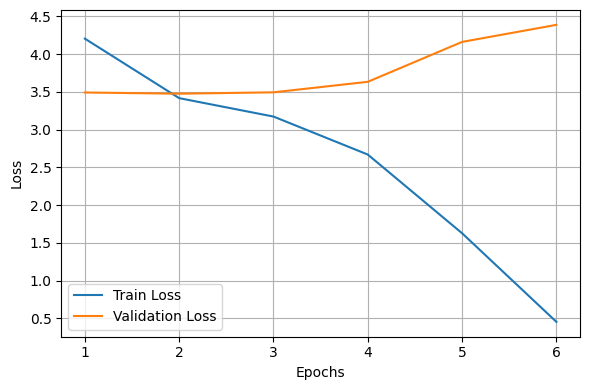

In [13]:

if __name__ == "__main__":
    dataset_dir = "./flickr_subset2/flickr_long_subset"
    captions_csv_path = os.path.join(dataset_dir, "captions.csv")
    model_dir = "./models_forclip"

    clip_model, clip_loaded, tokenizer, history = run_clip_training_with_your_dataset_fn(
        captions_csv_path=captions_csv_path,
        model_dir=model_dir,
        vocab_size=10000,
        sequence_length=32,
        embed_dim=128,
        batch_size=32,
        epochs=10,
        lr=1e-4,
        temperature=0.07
    )

    plot_training_curves(history, save_path=os.path.join(model_dir, "train_curves_clip.png"))


# Inference
## Paths / Config

In [14]:

dataset_dir = "./flickr_subset2/flickr_long_subset"
captions_csv_path = os.path.join(dataset_dir, "captions.csv")

model_dir = "./models_forclip"
model_name = "clip_model.keras"
vocab_path = os.path.join(model_dir, "vocab.txt")

image_dir = os.path.join(dataset_dir, "images")

sequence_length = 32
image_size = (224, 224)

os.makedirs(model_dir, exist_ok=True)


# Inference
## Image loading (224x224)


In [15]:
def load_img_224(path: str) -> tf.Tensor:
    x = tf.io.read_file(path)
    x = tf.image.decode_jpeg(x, channels=3)
    x = tf.image.resize(x, image_size)
    x = tf.image.convert_image_dtype(x, tf.float32)  # [0,1]
    return x

def preprocess_image_for_query(image_path: str) -> tf.Tensor:
    x = load_img_224(image_path)
    return tf.expand_dims(x, axis=0)  # (1,224,224,3)


# Inference
## Tokenizer from vocab.txt


In [16]:
def load_vocab_txt(path: str) -> list[str]:
    with open(path, "r", encoding="utf-8") as f:
        return [line.strip() for line in f if line.strip()]

def build_tokenizer_from_vocab(vocab: list[str], seq_len: int) -> TextVectorization:
    tok = TextVectorization(
        output_sequence_length=seq_len,
        standardize=None,   # keep exactly as training expected
    )
    tok.set_vocabulary(vocab)
    return tok

vocab = load_vocab_txt(vocab_path)
text_tokenizer = build_tokenizer_from_vocab(vocab, sequence_length)
print("✅ Tokenizer ready | vocab size:", len(vocab))


✅ Tokenizer ready | vocab size: 4121


# Inference
## Build encoders (image + text) from loaded CLIP


In [17]:
clip = tf.keras.models.load_model(
    os.path.join(model_dir, model_name),
    custom_objects={
        "L2Normalize": L2Normalize,
        "MaskedMean": MaskedMean,
        "PositionalEmbedding": PositionalEmbedding,
        "TransformerBlock": TransformerBlock,
        "SmallBERT": SmallBERT,
        "ClipLossLayer": ClipLossLayer,
    },
)

image_encoder = clip.get_layer("image_encoder")
print("✅ image_encoder:", image_encoder.output_shape)

try:
    text_encoder = clip.get_layer("text_encoder")
    print("✅ text_encoder:", text_encoder.output_shape)
except Exception:
    text_encoder = None
    print("⚠️ 'text_encoder' not found. Text→Image search disabled.")


✅ image_encoder: (None, 128)
✅ text_encoder: (None, 128)


# Inference
## Search helpers (dot product; assumes embeddings are L2-normalized)


In [18]:
def search_images_by_text(query: str, image_embeds: np.ndarray, image_paths: list[str], top_k: int = 5):
    if text_tokenizer is None or text_encoder is None:
        raise RuntimeError("text_tokenizer/text_encoder not initialized.")

    q_tokens = text_tokenizer([query])                  # (1,L)
    q_embed = text_encoder.predict(q_tokens, verbose=0) # (1,D)

    scores = (q_embed @ image_embeds.T)[0]              # (N,)
    idx = np.argsort(-scores)[:top_k]
    return [(image_paths[i], float(scores[i])) for i in idx]

def search_texts_by_image(image_path: str, text_embeds: np.ndarray, captions: list[str], cap_img_paths: list[str], top_k: int = 5):
    if image_encoder is None:
        raise RuntimeError("image_encoder not initialized.")

    img = preprocess_image_for_query(image_path)
    q_embed = image_encoder.predict(img, verbose=0)     # (1,D)

    scores = (q_embed @ text_embeds.T)[0]               # (N,)
    idx = np.argsort(-scores)[:top_k]
    return [(captions[i], cap_img_paths[i], float(scores[i])) for i in idx]

def show_topk_images(results, title="Top images", max_cols=5):
    n = len(results)
    cols = min(max_cols, n)
    rows = (n + cols - 1) // cols

    plt.figure(figsize=(4 * cols, 4 * rows))
    plt.suptitle(title, fontsize=14)

    for i, (p, s) in enumerate(results):
        ax = plt.subplot(rows, cols, i + 1)
        ax.imshow(mpimg.imread(p))
        ax.axis("off")
        ax.set_title(f"{s:.3f}", fontsize=10)

    plt.tight_layout()
    plt.show()

def print_topk_captions(results, title="Top captions"):
    print(title)
    for rank, (cap, img_p, s) in enumerate(results, start=1):
        print(f"{rank:02d}. score={s:.4f} | caption={cap} | image_path={img_p}")


# Inference
##  Build or load IMAGE index (image embeddings)


In [19]:
def save_image_index(path: str, embeds: np.ndarray, paths: list[str]):
    np.savez_compressed(
        path,
        embeds=embeds.astype("float32"),
        paths=np.array(paths, dtype=np.str_),
    )

def load_image_index(path: str):
    data = np.load(path, allow_pickle=False)
    return data["embeds"].astype("float32"), data["paths"].astype(str).tolist()

image_index_path = os.path.join(model_dir, "image_index.npz")

gallery_paths = [str(p) for p in Path(image_dir).rglob("*.jpg")]
print("📸 images found:", len(gallery_paths))
assert len(gallery_paths) > 0, f"No .jpg images found in {image_dir}"

if not os.path.exists(image_index_path):
    ds_gallery = (
        tf.data.Dataset.from_tensor_slices(gallery_paths)
        .map(load_img_224, num_parallel_calls=AUTOTUNE)
        .batch(64)
        .prefetch(AUTOTUNE)
    )

    print("🔄 Computing image embeddings...")
    gallery_embeds = image_encoder.predict(ds_gallery, verbose=1)
    print("✅ image embeds:", gallery_embeds.shape)

    save_image_index(image_index_path, gallery_embeds, gallery_paths)
    print("✅ Saved:", image_index_path)
else:
    print("✅ Using existing:", image_index_path)

image_embeds, image_paths = load_image_index(image_index_path)
print("✅ Loaded image index:", image_embeds.shape, "| paths:", len(image_paths))


📸 images found: 800
✅ Using existing: ./models_forclip/image_index.npz
✅ Loaded image index: (800, 128) | paths: 800


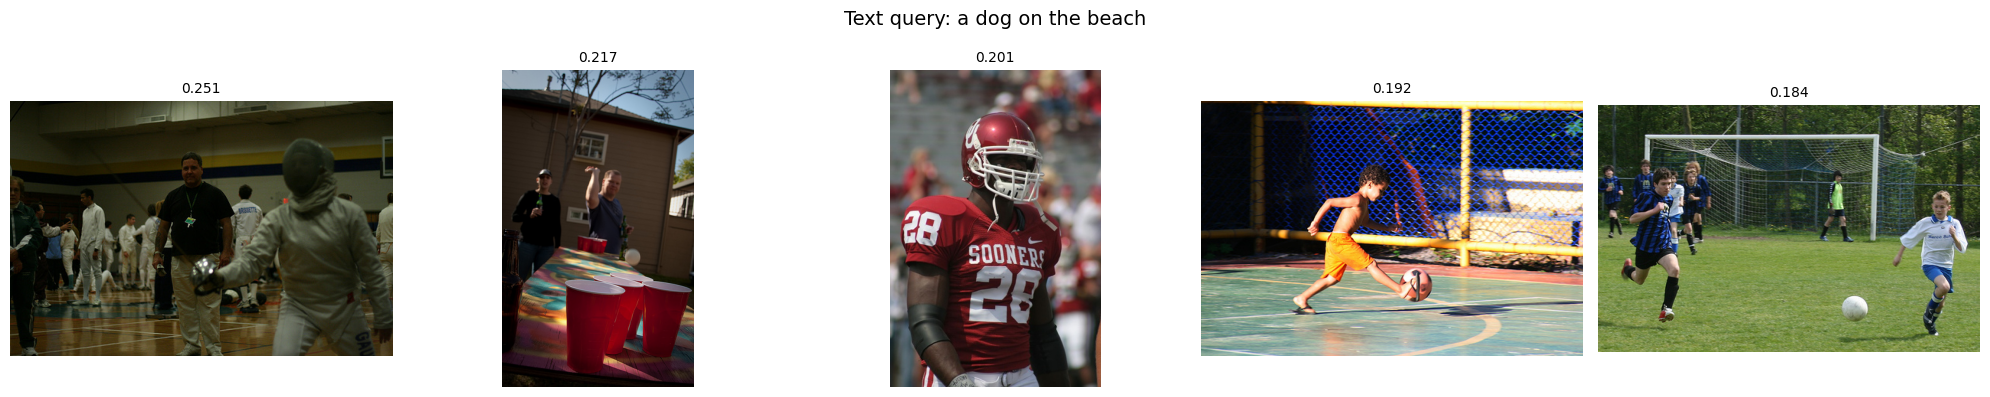

In [20]:
# Cell 10 — Demo: Text → Images
if text_encoder is not None:
    query = "a dog on the beach"
    results = search_images_by_text(query, image_embeds, image_paths, top_k=5)
    show_topk_images(results, title=f"Text query: {query}")
else:
    print("Text→Image disabled (no text_encoder).")


In [21]:
# Cell 11 — Caption index (caption embeddings) build/load/save
def build_caption_index(
    captions_csv_path: str,
    img_col: str = "image_path",
    cap_col: str = "caption",
    images_subdir: str = "images",
    drop_missing: bool = True,
):
    if text_tokenizer is None or text_encoder is None:
        raise RuntimeError("text_tokenizer/text_encoder must be initialized to embed captions.")

    df = pd.read_csv(captions_csv_path)
    if img_col not in df.columns or cap_col not in df.columns:
        raise ValueError(f"CSV must contain columns '{img_col}' and '{cap_col}'. Found: {list(df.columns)}")

    captions = df[cap_col].astype(str).tolist()
    raw_paths = df[img_col].astype(str).tolist()

    images_dir = os.path.join(dataset_dir, images_subdir)

    def resolve_path(p: str) -> str:
        p = p.strip()
        if os.path.isabs(p):
            return p
        if os.path.exists(p):
            return p
        cand1 = os.path.join(dataset_dir, p)
        if os.path.exists(cand1):
            return cand1
        return os.path.join(images_dir, p)

    cap_img_paths = [resolve_path(p) for p in raw_paths]

    if drop_missing:
        keep = [i for i, p in enumerate(cap_img_paths) if os.path.exists(p)]
        if len(keep) < len(cap_img_paths):
            print(f"⚠️ Dropping {len(cap_img_paths) - len(keep)} rows with missing image files.")
        captions = [captions[i] for i in keep]
        cap_img_paths = [cap_img_paths[i] for i in keep]

    ds_caps = tf.data.Dataset.from_tensor_slices(captions).batch(256).prefetch(AUTOTUNE)

    all_embeds = []
    for batch in ds_caps:
        tokens = text_tokenizer(batch)                    # (B,L)
        embeds = text_encoder.predict(tokens, verbose=0)  # (B,D)
        all_embeds.append(embeds)

    text_embeds = np.concatenate(all_embeds, axis=0).astype("float32")
    return text_embeds, captions, cap_img_paths

def save_caption_index(path: str, text_embeds: np.ndarray, captions: list[str], cap_img_paths: list[str]):
    np.savez_compressed(
        path,
        embeds=text_embeds.astype("float32"),
        captions=np.array(captions, dtype=np.str_),
        paths=np.array(cap_img_paths, dtype=np.str_),
    )

def load_caption_index(path: str):
    data = np.load(path, allow_pickle=False)
    return (
        data["embeds"].astype("float32"),
        data["captions"].astype(str).tolist(),
        data["paths"].astype(str).tolist(),
    )

caption_index_path = os.path.join(model_dir, "caption_index.npz")
assert os.path.isfile(captions_csv_path), f"Missing captions CSV: {captions_csv_path}"

if not os.path.exists(caption_index_path):
    print("🔄 Building caption index...")
    text_embeds, captions, cap_img_paths = build_caption_index(captions_csv_path)
    save_caption_index(caption_index_path, text_embeds, captions, cap_img_paths)
    print("✅ Saved:", caption_index_path, "| embeds:", text_embeds.shape)
else:
    print("✅ Using existing:", caption_index_path)

text_embeds, captions, cap_img_paths = load_caption_index(caption_index_path)
print("✅ Loaded caption index:", text_embeds.shape, "| captions:", len(captions))


✅ Using existing: ./models_forclip/caption_index.npz
✅ Loaded caption index: (800, 128) | captions: 800


Top captions for image: ./flickr_subset2/flickr_long_subset/images/bike/bike_001.jpg
01. score=0.1901 | caption=A sunny afternoon in a park with lush green grass and tall trees, a blond woman in casual clothing laughs as she throws a stick for her energetic orange dog to catch. The dog, its fur fluffed up from excitement, leaps into the air with an acrobatic twist, its paws outstretched in pursuit of the flying stick. As the dog bounds towards it, the woman's eyes light up with delight at the joyous display of canine enthusiasm. | image_path=./flickr_subset2/flickr_long_subset/images/dog/dog_615.jpg
02. score=0.1844 | caption=A woman in a blue tank top and shorts is jogging down an asphalt road, her ponytail bouncing with each step, while to her left, a cyclist wearing a yellow jersey and matching helmet pedals steadily towards her, the rhythmic sound of his wheels on the pavement filling the air as he passes by. The sun casts long shadows across the road behind him, illuminating the s

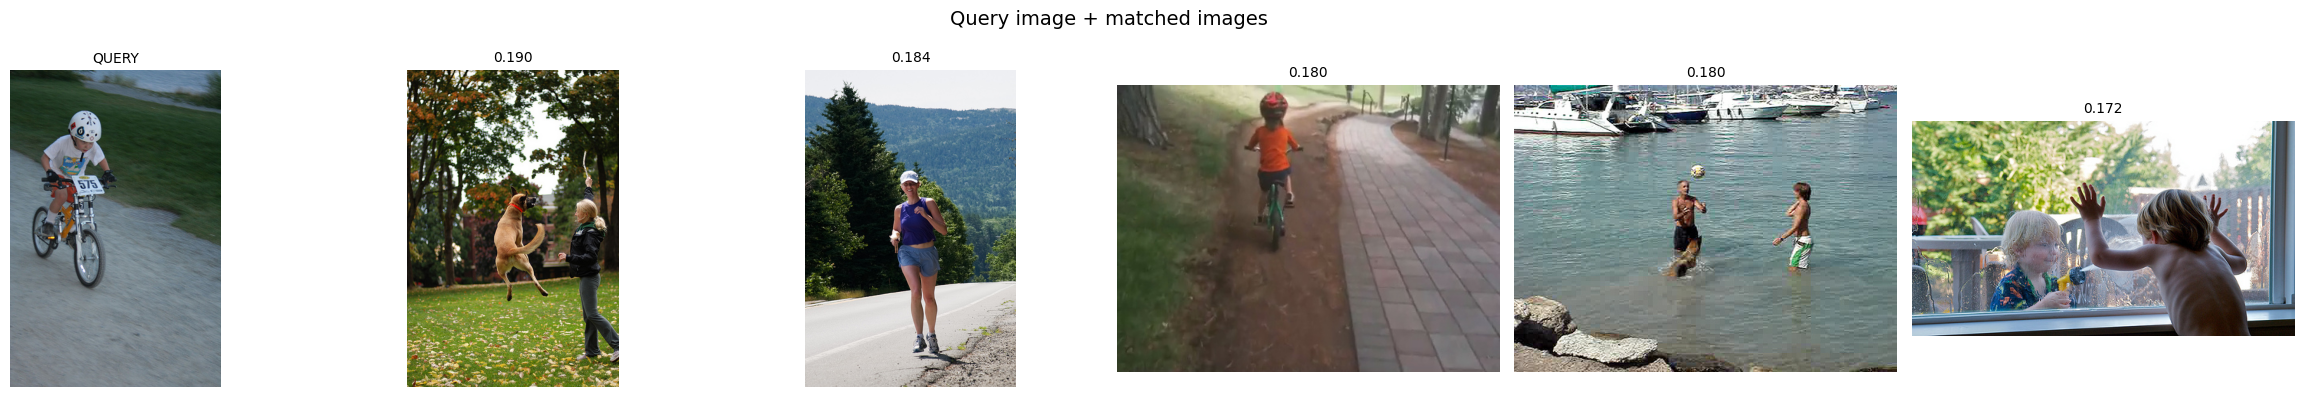

In [22]:
# Cell 12 — Demo: Image → Captions (+ optional matched images view)
def show_query_and_matches(query_image_path: str, results, max_cols=6):
    # We want to show: 1 query + len(results) matches
    total = 1 + len(results)
    cols = min(max_cols, total)
    rows = (total + cols - 1) // cols

    plt.figure(figsize=(4 * cols, 4 * rows))
    plt.suptitle("Query image + matched images", fontsize=14)

    # 1) Query image
    ax = plt.subplot(rows, cols, 1)
    ax.imshow(mpimg.imread(query_image_path))
    ax.axis("off")
    ax.set_title("QUERY", fontsize=10)

    # 2) Matched images
    for j, (_, img_p, s) in enumerate(results, start=2):
        ax = plt.subplot(rows, cols, j)
        ax.imshow(mpimg.imread(img_p))
        ax.axis("off")
        ax.set_title(f"{s:.3f}", fontsize=10)

    plt.tight_layout()
    plt.show()

query_image_path = cap_img_paths[0]
results = search_texts_by_image(query_image_path, text_embeds, captions, cap_img_paths, top_k=5)

print_topk_captions(results, title=f"Top captions for image: {query_image_path}")
show_query_and_matches(query_image_path, results)
